# Тема 7. Анализ характеристик музыкальных треков для поиска паттернов популярности и жанровой принадлежности

**Студент:** Виноградова Валерия Михайловна, группа ИД24-3



## 2.1. Анализ целей проекта

**Бизнес-цели**

1. Предсказать популярность трека до выпуска (для лейблов).
2. Определять жанр трека по его звучанию (для рекомендаций на платформах).
3. Показать маркетологам, как меняется музыка по годам и языкам (страны в данных нет, поэтому вместо регионов используем язык трека).

**Критерии достижения целей**

1. Прогноз популярности: лучшая модель даёт R² ≥ 0,30, и минимум 3 признака значимо связаны с популярностью (p < 0,05, |r| ≥ 0,1).
2. Определение жанра: лучшая модель даёт macro-F1 ≥ 0,50 на 6–8 крупных жанрах.
3. Тренды: минимум 3 признака значимо меняются с годами (p < 0,05); динамика показана по годам и языкам.

Пояснения:
* R² показывает, какую долю разброса популярности объясняет модель (от 0 до 1). Порог 0,30, потому что популярность сильно зависит от известности исполнителя и рекламы, а их в данных нет.
* macro-F1 — средняя точность по всем жанрам, где каждый жанр весит одинаково. Обычная точность не подходит: если 80 % треков поп, модель может всегда отвечать «поп» и выглядеть точной.
* Кроме p-value смотрим на силу связи r: при десятках тысяч треков значимой получается даже очень слабая связь.

**Объект:** музыкальные треки из Spotify, Discogs, Deezer, Pitchfork.
**Предмет:** связь характеристик звучания (`energy`, `danceability`, `valence`, `loudness`, `tempo`) с популярностью и жанром.
**Границы:** треки 2010–2024 годов.

**Гипотеза:** популярность трека зависит от характеристик его звучания, и в разных жанрах эта зависимость разная.

Проверяем её через пять вопросов:

| | Вопрос | Считаем подтверждённым, если |
|---|---|---|
| H1 | Влияют ли характеристики на популярность? | минимум 3 признака: p < 0,05 и \|r\| ≥ 0,1 |
| H2 | Можно ли предсказать популярность? | R² ≥ 0,30 |
| H3 | Можно ли определить жанр по звучанию? | macro-F1 ≥ 0,50 |
| H4 | Различается ли влияние признаков по жанрам? | учёт жанра значимо улучшает модель (p < 0,05) |
| H5 | Меняется ли музыка по годам? | минимум 3 признака значимо меняются с годами (p < 0,05) |

## 2.2. Подбор источников данных и выбор характеристик

По методичке нужен минимум один источник каждого типа. Выбраны четыре источника:

| № | Источник | Формат | Зачем |
|---|---|---|---|
| 1 | Spotify tracks (Kaggle) | CSV, реляционный | аудио-признаки и целевая `popularity` |
| 2 | Discogs masters | XML, иерархический | жанры и стили (целевая переменная классификации) |
| 3 | Deezer API | JSON, API | независимая популярность (`rank`), `bpm`, `gain` |
| 4 | Pitchfork Reviews (Kaggle) | SQLite + текст | жанры, оценки критиков, тексты рецензий |

В таблице Spotify нет жанра, поэтому жанры берём из Discogs (около 15 крупных жанров) и Pitchfork (9 жанров). Страны релиза в выбранных источниках нет, региональный срез делаем по языку трека (`language`, Spotify). Дамп Discogs большой (около 600 МБ), поэтому он читается потоком из интернета, а результат сохраняется в `discogs_raw.csv`.

In [1]:
import time, os, re, gzip, sqlite3, datetime, json
import urllib.request, urllib.parse
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

YEAR_MIN, YEAR_MAX = 2010, 2024
timings = {}   # сюда пишем время каждого этапа

# сайт Discogs может не пускать запросы без User-Agent
headers = {'User-Agent': 'Mozilla/5.0 (TOBD course project)'}

def open_dump(path_or_url):
    # открывает дамп: локальный файл, если он есть, иначе поток из интернета
    if os.path.exists(path_or_url):
        return open(path_or_url, 'rb')
    return urllib.request.urlopen(urllib.request.Request(path_or_url, headers=headers))

### 1. Spotify tracks: реляционный набор (CSV)

Одна строка — один трек. Есть метаданные, аудио-признаки Spotify, год и целевая переменная `popularity` (0–100).

In [2]:
spotify_df = pd.read_csv('spotify_tracks.csv')

print(spotify_df.shape)
display(spotify_df.head(3))
print('пропусков (isnull):', spotify_df.isnull().sum().sum())

(62317, 22)


,track_id,track_name,artist_name,year,popularity,artwork_url,album_name,acousticness,danceability,duration_ms,...,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,track_url,language
0,2r0ROhr7pRN4MXDMT1fEmd,"Leo Das Entry (From ""Leo"")",Anirudh Ravichander,2024,59,https://i.scdn.co/image/ab67616d0000b273ce9c65...,"Leo Das Entry (From ""Leo"")",0.0241,0.753,97297.0,...,8.0,0.1000,-5.994,0.0,0.1030,110.997,4.0,0.459,https://open.spotify.com/track/2r0ROhr7pRN4MXD...,Tamil
1,4I38e6Dg52a2o2a8i5Q5PW,AAO KILLELLE,"Anirudh Ravichander, Pravin Mani, Vaishali Sri...",2024,47,https://i.scdn.co/image/ab67616d0000b273be1b03...,AAO KILLELLE,0.0851,0.780,207369.0,...,10.0,0.0951,-5.674,0.0,0.0952,164.995,3.0,0.821,https://open.spotify.com/track/4I38e6Dg52a2o2a...,Tamil
2,59NoiRhnom3lTeRFaBzOev,Mayakiriye Sirikiriye - Orchestral EDM,"Anirudh Ravichander, Anivee, Alvin Bruno",2024,35,https://i.scdn.co/image/ab67616d0000b27334a1dd...,Mayakiriye Sirikiriye (Orchestral EDM),0.0311,0.457,82551.0,...,2.0,0.0831,-8.937,0.0,0.1530,169.996,4.0,0.598,https://open.spotify.com/track/59NoiRhnom3lTeR...,Tamil


пропусков (isnull): 0


| Колонка | Что означает |
|---|---|
| `track_id` | уникальный id трека (ключ) |
| `track_name`, `album_name` | название трека и альбома |
| `artist_name` | исполнитель (если несколько, через запятую) |
| `year` | год выхода |
| `language` | язык трека |
| `popularity` | популярность 0–100 (целевая переменная) |
| `acousticness` | насколько звук акустический, 0–1 |
| `danceability` | пригодность для танца, 0–1 |
| `energy` | интенсивность и «шумность», 0–1 |
| `instrumentalness` | вероятность отсутствия вокала, 0–1 |
| `liveness` | вероятность живой записи, 0–1 |
| `speechiness` | доля речи, 0–1 |
| `valence` | позитивность настроения, 0–1 |
| `loudness` | средняя громкость, дБ |
| `tempo` | темп, ударов в минуту |
| `duration_ms` | длительность, мс |
| `key`, `mode` | тональность (0–11) и лад (1 мажор, 0 минор) |
| `time_signature` | музыкальный размер (доли в такте) |
| `artwork_url`, `track_url` | ссылки на обложку и трек (служебные) |

Колонки с жанром в таблице нет, поэтому жанры берём из Discogs и Pitchfork.

### 2. Discogs masters: иерархический набор (XML)

Discogs каждый месяц выкладывает дампы в формате XML. Берём файл `masters`: один мастер-релиз — один альбом или сингл, независимо от переизданий. У каждого мастера есть жанры (`genres`) и стили (`styles`). Дампы лежат на `data.discogs.com`. Файл `masters` весит около 600 МБ в архиве; мы читаем его прямо из интернета через `gzip` и `iterparse`. 

In [4]:
discogs_url = 'https://data.discogs.com/?download=data%2F2026%2Fdiscogs_20261101_masters.xml.gz'

def print_tree(el, level=0):
    print('  ' * level + el.tag)
    seen = set()
    for child in el:
        if child.tag not in seen:
            seen.add(child.tag)
            print_tree(child, level + 1)

# берём из дампа только первый мастер-релиз (скачивается лишь начало файла)
resp = open_dump(discogs_url)
gz = gzip.GzipFile(fileobj=resp)
for event, el in ET.iterparse(gz, events=('end',)):
    if el.tag == 'master':
        first_master = el
        break
resp.close()

print('Дерево тегов одного мастер-релиза')
print_tree(first_master)

print('\nГлавные поля этого мастер-релиза')
print('id:     ', first_master.get('id'))
print('title:  ', first_master.findtext('title'))
print('year:   ', first_master.findtext('year'))
print('genres: ', [g.text for g in first_master.findall('genres/genre')])
print('styles: ', [s.text for s in first_master.findall('styles/style')])

Дерево тегов одного мастер-релиза
master
  main_release
  artists
    artist
      id
      name
      join
  genres
    genre
  styles
    style
  year
  title
  data_quality
  videos
    video
      title
      description

Главные поля этого мастер-релиза
id:      113
title:   Moments In Time
year:    2002
genres:  ['Electronic']
styles:  ['Techno', 'Tech House']


**Пример записи: первый мастер-релиз целиком.** Каждый тег на своей строке, вложенные теги сдвинуты вправо. Так видна иерархия: `master` → `artists` → `artist` → `name`, `genres` → `genre`, `styles` → `style`.

In [5]:
ET.indent(first_master)
print('Первый <master>')
print(ET.tostring(first_master, encoding='unicode')[:1500])

Первый <master>
<master id="113">
  <main_release>116925</main_release>
  <artists>
    <artist>
      <id>3225</id>
      <name>Vince Watson</name>
      <join>,</join>
    </artist>
  </artists>
  <genres>
    <genre>Electronic</genre>
  </genres>
  <styles>
    <style>Techno</style>
    <style>Tech House</style>
  </styles>
  <year>2002</year>
  <title>Moments In Time</title>
  <data_quality>Correct</data_quality>
  <videos>
    <video src="https://www.youtube.com/watch?v=dhbf58AU5ek" duration="321" embed="true">
      <title>Out of the Deep</title>
      <description>Provided to YouTube by EPM Online

Out of the Deep · Vince Watson

Alola Vol 1

℗ Westbury Music Ltd / Spherecom Music

Released on: 1999-05-02

Auto-generated by YouTube.</description>
    </video>
    <video src="https://www.youtube.com/watch?v=xWY_I9QuWZM" duration="355" embed="true">
      <title>Mystical Rhythm</title>
      <description>Provided to YouTube by EPM Online

Mystical Rhythm · Vince Watson

Alola Vol 

### 3. Deezer API: источник с API и выдачей в JSON

Открытый API Deezer работает без ключа. Для трека он отдаёт `rank` (независимая мера популярности), `bpm`, `gain` (громкость в дБ), длительность, дату выхода, `isrc` и флаг `explicit_lyrics`. Сначала ищем трек по исполнителю и названию, потом запрашиваем его карточку по `id`.

In [6]:
found = requests.get('https://api.deezer.com/search', params={'q': 'A.R. Rahman Dil Se Re', 'limit': 3}).json()
print('найдено результатов:', found['total'])
print(list(found['data'][0].keys()))

track = requests.get(f"https://api.deezer.com/track/{found['data'][0]['id']}").json()
print({k: track[k] for k in ['title', 'rank', 'bpm', 'gain', 'duration', 'release_date', 'isrc', 'explicit_lyrics']})

найдено результатов: 4
['id', 'readable', 'title', 'title_short', 'title_version', 'isrc', 'link', 'duration', 'rank', 'explicit_lyrics', 'explicit_content_lyrics', 'explicit_content_cover', 'preview', 'md5_image', 'artist', 'album', 'type']
{'title': 'Dil Se Re', 'rank': 248698, 'bpm': 0, 'gain': -17.4, 'duration': 405, 'release_date': '1998-07-08', 'isrc': 'INV119800031', 'explicit_lyrics': False}


In [7]:
print(json.dumps(found['data'][0], indent=2, ensure_ascii=False))   # первый результат поиска

{
  "id": 127772713,
  "readable": true,
  "title": "Dil Se Re",
  "title_short": "Dil Se Re",
  "title_version": "",
  "isrc": "INV119800031",
  "link": "https://www.deezer.com/track/127772713",
  "duration": 405,
  "rank": 248698,
  "explicit_lyrics": false,
  "explicit_content_lyrics": 0,
  "explicit_content_cover": 2,
  "preview": "https://cdnt-preview.dzcdn.net/api/1/1/e/6/0/0/e60e0bfc4ebc34df5216b40ecdb7f803.mp3?hdnea=exp=1794773183~acl=/api/1/1/e/6/0/0/e60e0bfc4ebc34df5216b40ecdb7f803.mp3*~data=user_id=0,application_id=42~hmac=b950b3a376ed89f9da4bc5c0276717f7ac19949f63830eccedb41a2d859191af",
  "md5_image": "352ed3819432c7442ebe203d74f08ac0",
  "artist": {
    "id": 491,
    "name": "A.R. Rahman",
    "link": "https://www.deezer.com/artist/491",
    "picture": "https://api.deezer.com/artist/491/image",
    "picture_small": "https://cdn-images.dzcdn.net/images/artist/bd34315ef977a62a9e28c1ab19bb8ac4/56x56-000000-80-0-0.jpg",
    "picture_medium": "https://cdn-images.dzcdn.net/ima

* `id` — номер трека
* `readable` — можно ли воспроизвести трек (да/нет)
* `title` — название
* `title_short` — короткое название
* `title_version` — версия (например, Live, Remastered)
* `isrc` — международный код записи
* `link` — ссылка на трек
* `duration` — длительность, секунды
* `rank` — рейтинг популярности: чем больше, тем популярнее
* `explicit_lyrics` — есть ли откровенный текст (да/нет)
* `explicit_content_lyrics` — то же, но числом-кодом
* `explicit_content_cover` — откровенная ли обложка (число-код)
* `preview` — ссылка на 30 секунд трека
* `md5_image` — код обложки
* `artist` — исполнитель (внутри: id, имя)
* `album` — альбом (внутри: id, название)
* `type` — тип объекта, здесь всегда `track` (трек)

### 4. Pitchfork Reviews: SQLite и неструктурированный текст

База рецензий на альбомы. Таблица `reviews` — оценка критика (`score`), год, автор; `genres` — жанры альбома; `content` — полный текст рецензии. Текст — неструктурированные данные, в 2.3 мы его векторизуем.

In [8]:
conn = sqlite3.connect('database.sqlite')
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
display(pd.read_sql("SELECT reviewid, title, artist, score, best_new_music, pub_year FROM reviews LIMIT 3", conn))
text = pd.read_sql("SELECT content FROM content LIMIT 1", conn).iloc[0, 0]
print(text[:300])
conn.close()

      name
0  reviews
1  artists
2   genres
3   labels
4    years
5  content


,reviewid,title,artist,score,best_new_music,pub_year
0,22703,mezzanine,massive attack,9.3,0,2017
1,22721,prelapsarian,krallice,7.9,0,2017
2,22659,all of them naturals,uranium club,7.3,0,2017


“Trip-hop” eventually became a ’90s punchline, a music-press shorthand for “overhyped hotel lounge music.” But today, the much-maligned subgenre almost feels like a secret precedent. Listen to any of the canonical Bristol-scene albums of the mid-late ’90s, when the genre was starting to chafe agains


### 5. Итог: выбранные характеристики

**Итог 2.2.**

* Целевые переменные: `popularity` (Spotify, регрессия; проверка по `rank` Deezer) и жанр (Discogs и Pitchfork, классификация).
* Предикторы гипотезы: `energy`, `danceability`, `valence`, `loudness`, `tempo` (Spotify) и их аналоги `bpm`, `gain` (Deezer).
* Факторы влияния: год, язык трека (срез вместо региона), стили Discogs, оценка критика и текст рецензии (Pitchfork), `explicit` (Deezer).
* Требования методички выполнены: реляционный набор (Spotify, Pitchfork), иерархический XML (Discogs), API с JSON (Deezer), неструктурированные данные (тексты рецензий). В каждом источнике не меньше 3 числовых и 3 категориальных характеристик, везде есть время.

## 2.3. Подготовка данных 

### 1. Spotify (CSV): загрузка, пропуски, очистка

In [9]:
t0 = time.time()
spotify_df = pd.read_csv('spotify_tracks.csv')
timings['1.1 Spotify: загрузка'] = round(time.time() - t0, 2)

audio_cols = ['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness',
              'speechiness', 'valence', 'loudness', 'tempo', 'duration_ms', 'popularity']
display(spotify_df[audio_cols].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
acousticness,62317.0,0.362,0.315,-1.0,0.067,0.286,0.632,0.996
danceability,62317.0,0.597,0.186,-1.0,0.497,0.631,0.730,0.986
energy,62317.0,0.602,0.246,-1.0,0.440,0.639,0.803,1.000
instrumentalness,62317.0,0.146,0.308,-1.0,0.000,0.000,0.015,0.999
liveness,62317.0,0.194,0.172,-1.0,0.093,0.125,0.243,0.998
speechiness,62317.0,0.088,0.115,-1.0,0.037,0.049,0.089,0.959
valence,62317.0,0.495,0.265,-1.0,0.292,0.507,0.710,0.995
loudness,62317.0,-65.103,2369.051,-100000.0,-10.727,-7.506,-5.456,1.233
tempo,62317.0,117.931,28.509,-1.0,95.942,117.991,135.081,239.970
duration_ms,62317.0,242527.040,112999.933,5000.0,192160.000,236267.000,286240.000,4581483.000


In [10]:
t0 = time.time()
sp = spotify_df.drop_duplicates('track_id')
sp = sp[sp['year'].between(YEAR_MIN, YEAR_MAX)]

# isnull() показал 0 пропусков, но в describe() видны заглушки -1 и -100000: так закодированы пропуски
share_cols = ['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'speechiness', 'valence']
sp = sp[(sp[share_cols] >= 0).all(axis=1) & (sp['loudness'] > -60) & (sp['tempo'] > 0) & (sp['duration_ms'] > 0)].copy()
timings['1.2 Spotify: очистка'] = round(time.time() - t0, 2)

print(len(spotify_df), '->', len(sp), '| доля popularity = 0:', round((sp['popularity'] == 0).mean(), 3))

62317 -> 49212 | доля popularity = 0: 0.282


**Вывод.** Пропусков `isnull()` не находит, но они закодированы заглушками: −1 у признаков от 0 до 1 и −100000 у `loudness`. После удаления дублей, заглушек и треков вне 2010–2024 осталось 49 212 из 62 317 треков. У 28 % треков `popularity = 0`. Скорее всего, это отсутствие данных о прослушиваниях, а не реальный ноль; учтём это в 2.4.

Для слияния нужны ключи. Названия приводим к нижнему регистру, убираем скобки вроде (feat. X) и [Remastered], суффиксы  - Live и знаки препинания; у списка исполнителей берём первого.

In [11]:
def norm(s):
    s = str(s).casefold() if pd.notna(s) else ''
    s = re.sub(r'\(.*?\)|\[.*?\]', ' ', s)    # (feat. X), [Remastered], (2) у Discogs
    s = re.sub(r'\s+-\s+.*$', '', s)          # " - Live"
    s = re.sub(r'[^\w\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

def main_artist(s):
    s = str(s) if pd.notna(s) else ''
    return re.split(r',|;|\sfeat\.?\s|\sft\.?\s|\s&\s|\sx\s', s)[0]

def make_key(artist, name):
    a = artist.map(main_artist).map(norm)
    n = name.map(norm)
    return (a + '|' + n).where((a != '') & (n != ''))   # пустой ключ -> NaN

sp['key_aa'] = make_key(sp['artist_name'], sp['album_name'])

### 2. Discogs masters (XML): чтение дампа из интернета

Читаем файл потоком: скачивается кусок, разбирается, память очищается. Оставляем только мастера 2010–2024. Полное чтение дампа занимает около 1 минуты. Результат сохраняется в `discogs_raw.csv`: при повторном запуске ноутбук берёт данные из файла и не скачивает дамп заново. Чтобы скачать свежий дамп, удалите `discogs_raw.csv`.

In [12]:
def read_discogs(url):
    rows = []
    events = ET.iterparse(gzip.GzipFile(fileobj=open_dump(url)), events=('start', 'end'))
    root = next(events)[1]      # корневой элемент: чистим его, чтобы память не росла
    for event, el in events:
        if event == 'end' and el.tag == 'master':
            year = int(el.findtext('year') or 0)
            if YEAR_MIN <= year <= YEAR_MAX:
                rows.append({
                    'master_id': el.get('id'), 'title': el.findtext('title'), 'year': year,
                    'artist': el.findtext('artists/artist/name'),
                    'genre': el.findtext('genres/genre'), 'style': el.findtext('styles/style'),
                    'n_genres': len(el.findall('genres/genre')), 'n_styles': len(el.findall('styles/style')),
                    'n_artists': len(el.findall('artists/artist')), 'n_videos': len(el.findall('videos/video')),
                    'data_quality': el.findtext('data_quality')})
            el.clear()
            root.clear()
    return pd.DataFrame(rows)

t0 = time.time()
if os.path.exists('discogs_raw.csv'):          # уже читали: берём из файла
    dc_raw = pd.read_csv('discogs_raw.csv')
else:                                            # первый запуск: читаем дамп из интернета
    dc_raw = read_discogs(discogs_url)
    dc_raw.to_csv('discogs_raw.csv', index=False)
timings['2.1 Discogs: чтение XML'] = round(time.time() - t0, 2)

print(len(dc_raw), 'мастеров за', YEAR_MIN, '-', YEAR_MAX)
print(dc_raw['genre'].value_counts())

695444 мастеров за 2010 - 2024
genre
Electronic                301812
Rock                      249480
Hip Hop                    36531
Pop                        32272
Jazz                       23731
Folk, World, & Country     15723
Classical                   8798
Funk / Soul                 8704
Reggae                      4756
Latin                       4175
Stage & Screen              3463
Blues                       2805
Non-Music                   2557
Children's                   551
Brass & Military              86
Name: count, dtype: int64


In [13]:
dc = dc_raw.drop_duplicates('master_id').dropna(subset=['title', 'artist']).copy()
dc = dc[~dc['artist'].str.lower().isin(['various', 'unknown artist'])]   # сборники
dc['key_aa'] = make_key(dc['artist'], dc['title'])
print(len(dc), 'мастеров;', dc['genre'].nunique(), 'жанров;', dc['style'].nunique(), 'стилей')

667718 мастеров; 15 жанров; 659 стилей


**Вывод.** За 2010–2024 годы в Discogs 668 тыс. мастер-релизов, 15 жанров и 659 стилей. Жанры сильно несбалансированы: на Electronic и Rock приходится около 80 % записей.

### 3. Deezer API (JSON): независимая популярность, bpm, gain

Берём случайную выборку из `N_DEEZER` треков Spotify. Для каждого: поиск → проверка, что исполнитель и название совпали → запрос карточки. Запросы идут в 5 потоков с паузой, чтобы не превысить лимит Deezer (около 10 запросов в секунду).

Результат сохраняется в `deezer_raw.csv`. При повторном запуске уже проверенные треки берутся из файла, а в API уходят запросы только по недостающим. Поэтому `N_DEEZER` можно увеличивать постепенно, не скачивая всё заново.

In [14]:
N_DEEZER = 3000          # сколько треков всего проверяем на Deezer
BATCH = 250              # сохраняем результат после каждой порции

def deezer_info(row):
    time.sleep(0.5)     # пауза, чтобы не превысить лимит Deezer
    a, t = main_artist(row['artist_name']), norm(row['track_name'])
    try:
        found = requests.get('https://api.deezer.com/search', params={'q': f'{a} {t}', 'limit': 5}, timeout=10).json()
        for c in found['data']:
            if norm(c['title']) == t and norm(c['artist']['name']) == norm(a):    # совпали название и исполнитель
                d = requests.get(f"https://api.deezer.com/track/{c['id']}", timeout=10).json()
                return {'track_id': row['track_id'], 'matched': True, 'dz_rank': d['rank'], 'dz_duration': d['duration'],
                        'dz_bpm': d['bpm'] or None, 'dz_gain': d['gain'], 'dz_explicit': d['explicit_lyrics'],
                        'dz_release_date': d['release_date'], 'dz_n_contributors': len(d['contributors']),
                        'dz_artist': c['artist']['name'], 'dz_album': c['album']['title']}
    except Exception:
        pass            # запрос не удался или не ответил за 10 с: считаем трек ненайденным
    return {'track_id': row['track_id'], 'matched': False}

t0 = time.time()
dz_raw = pd.read_csv('deezer_raw.csv') if os.path.exists('deezer_raw.csv') else pd.DataFrame(columns=['track_id', 'matched'])

# дозапрашиваем недостающее порциями и сохраняем после каждой, чтобы при сбое ничего не потерять
todo = sp[~sp['track_id'].isin(dz_raw['track_id'])].sample(max(N_DEEZER - len(dz_raw), 0), random_state=42)
for i in range(0, len(todo), BATCH):
    part = todo.iloc[i:i + BATCH]
    with ThreadPoolExecutor(max_workers=5) as ex:
        dz_raw = pd.concat([dz_raw, pd.DataFrame(list(ex.map(deezer_info, part.to_dict('records'))))], ignore_index=True)
    dz_raw.to_csv('deezer_raw.csv', index=False)
    print('проверено:', len(dz_raw), 'из', N_DEEZER, '|', round(time.time() - t0), 'с')
dz_raw['matched'] = dz_raw['matched'].astype(bool)

timings['3.1 Deezer: запросы к API'] = round(time.time() - t0, 2)
print('найдено на Deezer:', round(dz_raw['matched'].mean(), 3), 'из', len(dz_raw))

проверено: 250 из 3000 | 71 с
проверено: 500 из 3000 | 159 с
проверено: 750 из 3000 | 615 с
проверено: 1000 из 3000 | 686 с
проверено: 1250 из 3000 | 934 с
проверено: 1500 из 3000 | 1190 с
проверено: 1750 из 3000 | 1318 с
проверено: 2000 из 3000 | 1502 с
проверено: 2250 из 3000 | 1728 с
проверено: 2500 из 3000 | 1855 с
проверено: 2750 из 3000 | 2031 с
проверено: 3000 из 3000 | 2261 с
найдено на Deezer: 0.611 из 3000


In [15]:
dz = dz_raw[dz_raw['matched']].drop(columns='matched').copy()
print(len(dz), 'треков, из них с rank = 0:', (dz['dz_rank'] == 0).sum())
dz['dz_rank'] = dz['dz_rank'].replace(0, np.nan)    # rank = 0: данных о рейтинге нет, считаем пропуском
dz['dz_log_rank'] = np.log10(dz['dz_rank'])         # rank сильно скошен, берём логарифм
dz['dz_release_date'] = pd.to_datetime(dz['dz_release_date'], errors='coerce')

1833 треков, из них с rank = 0: 3


**Вывод.** Найденная на Deezer доля треков выведена выше; остальные не нашлись или не совпали по исполнителю и названию. `rank = 0` и `bpm = 0` означают, что данных нет, поэтому заменены на пропуски.

### 4. Pitchfork (SQLite + текст): жанры, оценки, векторизация рецензий

In [16]:
conn = sqlite3.connect('database.sqlite')
pf_rev = pd.read_sql("SELECT reviewid, title, artist, score, best_new_music, author, pub_year FROM reviews", conn)
pf_gen = pd.read_sql("SELECT reviewid, genre FROM genres", conn)
pf_txt = pd.read_sql("SELECT reviewid, content FROM content", conn)
conn.close()

# у альбома может быть несколько жанров: главный = первый
gen = pf_gen.dropna().groupby('reviewid')['genre'].agg(pf_genre='first', pf_n_genres='nunique').reset_index()
pf = pf_rev.merge(gen, on='reviewid', how='left').merge(pf_txt, on='reviewid', how='left').drop_duplicates('reviewid')
pf['pf_word_count'] = pf['content'].fillna('').str.split().str.len()
pf['key_aa'] = make_key(pf['artist'], pf['title'])
print(pf.shape)
print(pf['pf_genre'].value_counts(dropna=False))

(18389, 12)
pf_genre
rock            9435
NaN             2365
electronic      1994
rap             1488
pop/r&b         1087
folk/country     574
experimental     565
metal            357
jazz             341
global           183
Name: count, dtype: int64


**Векторизация текста.** TF-IDF превращает каждую рецензию в вектор слов, а LSA (усечённое SVD) сжимает его до 50 чисел, которые можно подавать в модели. Для аннотирования смотрим характерные слова каждого жанра.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

t0 = time.time()
tfidf = TfidfVectorizer(max_features=20000, stop_words='english', min_df=5, max_df=0.5, sublinear_tf=True)
X = tfidf.fit_transform(pf['content'].fillna(''))
svd = TruncatedSVD(n_components=50, random_state=42)
Z = svd.fit_transform(X)
timings['4.2 Pitchfork: TF-IDF + LSA'] = round(time.time() - t0, 2)

pf_vec = pd.DataFrame(Z, columns=[f'txt_lsa_{i:02d}' for i in range(50)])
pf_vec.insert(0, 'reviewid', pf['reviewid'].values)
print(X.shape, '| объяснено дисперсии:', round(svd.explained_variance_ratio_.sum(), 3))

words = np.array(tfidf.get_feature_names_out())
for g in pf['pf_genre'].dropna().unique():
    idx = np.where(pf['pf_genre'].values == g)[0]
    top = np.asarray(X[idx].mean(axis=0)).ravel().argsort()[::-1][:8]
    print(g, ':', ', '.join(words[top]))

(18389, 20000) | объяснено дисперсии: 0.037
electronic : tracks, techno, electronic, dance, house, bass, work, beats
metal : metal, black, death, hardcore, doom, riffs, minutes, bands
rock : rock, pop, ve, love, best, little, don, make
rap : rap, rapper, hop, hip, beats, rappers, mixtape, rapping
experimental : work, piece, noise, pieces, composer, electronic, tracks, long
folk/country : folk, country, voice, acoustic, sings, love, old, work
jazz : jazz, playing, work, bass, free, tracks, piano, piece
pop/r&b : pop, love, voice, best, tracks, debut, little, good
global : reggae, fela, african, africa, world, mali, dancehall, afrobeat


**Вывод.** Характерные слова совпадают с жанрами (techno, house — electronic; rapper, mixtape — rap; reggae, afrobeat — global). Значит, тексты рецензий несут жанровую информацию. 50 компонент LSA объясняют около 4 % дисперсии. Для текстов это нормально: словарь большой, и каждая компонента описывает только одну тему.

### 5. Типы шкал, аналитические роли и общие атрибуты

| Атрибут | Источник | Тип шкалы | Аналитическая роль |
|---|---|---|---|
| `popularity` | Spotify | отношений | **целевая** (регрессия) |
| `dz_rank` (и его log10) | Deezer | отношений | целевая-2 (независимая проверка популярности) |
| `energy`, `danceability`, `valence`, `acousticness`, `speechiness`, `instrumentalness`, `liveness` | Spotify | интервальная | признак |
| `loudness` | Spotify | интервальная | признак |
| `tempo`, `duration_ms` | Spotify | отношений | признак |
| `key`, `mode`, `time_signature` | Spotify | номинальная | признак |
| `language` | Spotify | номинальная | срез (регион) |
| `dz_bpm`, `dz_gain`, `dz_explicit` | Deezer | отношений / номинальная | признак, сверка со Spotify |
| `genre`, `style` | Discogs | номинальная | **целевая** (классификация жанров) |
| `pf_genre` | Pitchfork | номинальная | целевая-2 (жанры) |
| `score` | Pitchfork | порядковая | признак (оценка критика) |
| `txt_lsa_00…49` | Pitchfork (текст) | интервальная | признак (текст рецензии) |
| `year` | все источники | интервальная (время) | общий атрибут, агрегаты по годам |
| `track_id` | Spotify, Deezer | номинальная | ключ слияния (точный) |
| исполнитель + альбом | Spotify, Discogs, Pitchfork | номинальная | ключ слияния (по нормализованным названиям) |

**Общие атрибуты для слияния:** `track_id` (Spotify и Deezer), исполнитель + альбом (Spotify, Discogs, Pitchfork), год (все источники).

### 6. Слияние разнородных данных

Три уровня: трек (точно по `track_id`: Spotify и Deezer), альбом (по ключу «исполнитель + альбом»: Spotify, Discogs, Pitchfork) и год (общая таблица по годам). Базой служит Spotify (`left join`), поэтому число строк не должно измениться.

In [18]:
t0 = time.time()
dc_agg = (dc.drop_duplicates('key_aa').dropna(subset=['key_aa'])
            [['key_aa', 'master_id', 'genre', 'style', 'n_styles', 'n_genres']]
            .add_prefix('dc_').rename(columns={'dc_key_aa': 'key_aa'}))

pf_agg = (pf.drop(columns='content').merge(pf_vec, on='reviewid')
            .dropna(subset=['key_aa']).drop_duplicates('key_aa').drop(columns=['title', 'artist'])
            .rename(columns={'score': 'pf_score', 'best_new_music': 'pf_bnm', 'author': 'pf_author', 'pub_year': 'pf_year'}))

merged = (sp.merge(dz.drop(columns=['dz_artist', 'dz_album']), on='track_id', how='left')
            .merge(dc_agg, on='key_aa', how='left')
            .merge(pf_agg, on='key_aa', how='left'))

# у Pitchfork другие названия жанров (rap, pop/r&b ...), приводим их к названиям Discogs
pf_to_discogs = {'electronic': 'Electronic', 'rock': 'Rock', 'metal': 'Rock', 'rap': 'Hip Hop', 'pop/r&b': 'Pop',
                 'folk/country': 'Folk, World, & Country', 'global': 'Folk, World, & Country',
                 'jazz': 'Jazz', 'experimental': 'Experimental'}
# единая колонка жанра: сначала Discogs, если нет - Pitchfork
merged['genre_unified'] = merged['dc_genre'].fillna(merged['pf_genre'].map(pf_to_discogs))
timings['6.1 Слияние'] = round(time.time() - t0, 2)

print(merged.shape)
for col in ['dz_rank', 'dc_genre', 'pf_score', 'genre_unified']:
    print(col, ': данные есть у', round(merged[col].notna().mean() * 100, 1), '% треков Spotify')
print(merged['genre_unified'].value_counts())

(49212, 95)
dz_rank : данные есть у 3.7 % треков Spotify
dc_genre : данные есть у 17.6 % треков Spotify
pf_score : данные есть у 1.5 % треков Spotify
genre_unified : данные есть у 17.6 % треков Spotify
genre_unified
Electronic                3150
Pop                       2296
Stage & Screen            1134
Rock                       896
Hip Hop                    713
Folk, World, & Country     156
Classical                  102
Funk / Soul                 82
Latin                       79
Jazz                        43
Reggae                      11
Name: count, dtype: int64


In [19]:
# сверка источников: измеряют ли они одно и то же
for a, b in [('tempo', 'dz_bpm'), ('loudness', 'dz_gain'), ('popularity', 'dz_log_rank')]:
    d = merged[[a, b]].dropna()
    print(a, '-', b, ': r =', round(d[a].corr(d[b]), 3), '| общих треков:', len(d))

tempo - dz_bpm : r = 0.053 | общих треков: 578
loudness - dz_gain : r = 0.813 | общих треков: 1833
popularity - dz_log_rank : r = 0.254 | общих треков: 1830


**Вывод.** Громкость в Spotify и Deezer хорошо согласована (r ≈ 0,81), значит, треки сопоставлены верно. Популярность связана слабо (r ≈ 0,25): у сервисов разные аудитории, поэтому `dz_rank` — дополнительная проверка, а не замена `popularity`. Темп почти не совпадает (r ≈ 0,05): `bpm` в Deezer заполнен лишь у части треков.

In [20]:
# общая таблица по годам (общий атрибут: год)
sp_y = sp.groupby('year').agg(sp_tracks=('track_id', 'size'), sp_popularity=('popularity', 'mean'), sp_energy=('energy', 'mean'),
                              sp_danceability=('danceability', 'mean'), sp_valence=('valence', 'mean'),
                              sp_loudness=('loudness', 'mean'), sp_tempo=('tempo', 'mean'))
dc_y = dc.groupby('year').agg(dc_masters=('master_id', 'size'))
pf_y = pf.groupby('pub_year').agg(pf_reviews=('reviewid', 'size'), pf_score=('score', 'mean'))

year_panel = pd.concat([sp_y, dc_y, pf_y], axis=1)
year_panel = year_panel[year_panel.index.isin(range(YEAR_MIN, YEAR_MAX + 1))].rename_axis('year').reset_index()
display(year_panel.round(3))

,year,sp_tracks,sp_popularity,sp_energy,sp_danceability,sp_valence,sp_loudness,sp_tempo,dc_masters,pf_reviews,pf_score
0,2010,1586.0,18.129,0.625,0.582,0.474,-8.770,118.754,39948.0,1170.0,6.973
1,2011,1621.0,19.303,0.615,0.575,0.473,-9.221,117.737,41536.0,1165.0,7.037
2,2012,1965.0,19.530,0.641,0.580,0.468,-8.140,119.316,44689.0,1185.0,7.012
3,2013,3360.0,13.505,0.630,0.625,0.545,-8.756,117.333,46207.0,1200.0,7.050
4,2014,2784.0,15.282,0.612,0.600,0.493,-8.708,117.007,46754.0,1162.0,7.082
5,2015,2624.0,16.082,0.643,0.606,0.503,-7.906,118.971,47096.0,1135.0,7.107
6,2016,2820.0,17.827,0.637,0.583,0.466,-8.124,117.437,48966.0,1265.0,7.246
7,2017,2896.0,16.578,0.633,0.579,0.475,-8.527,118.560,49510.0,17.0,7.365
8,2018,2967.0,15.249,0.615,0.583,0.457,-8.545,118.503,50575.0,NaN,NaN
9,2019,2806.0,16.882,0.612,0.574,0.452,-8.673,118.873,49474.0,NaN,NaN


**Вывод.** Число треков Spotify растёт к 2022–2024 годам, а средняя популярность в 2024 году заметно ниже: новые треки ещё не набрали прослушиваний. В 2.4 год нужно учитывать как признак.

In [21]:
print('Итоговая таблица:', merged.shape[0], 'треков,', merged.shape[1], 'колонок')

# в скольких источниках нашёлся трек (Spotify есть у всех)
n_src = 1 + merged['dz_rank'].notna() + merged['dc_genre'].notna() + merged['pf_score'].notna()
print(n_src.value_counts().sort_index().rename_axis('источников').rename('треков'))

Итоговая таблица: 49212 треков, 95 колонок
источников
1    39130
2     8957
3     1081
4       44
Name: треков, dtype: int64


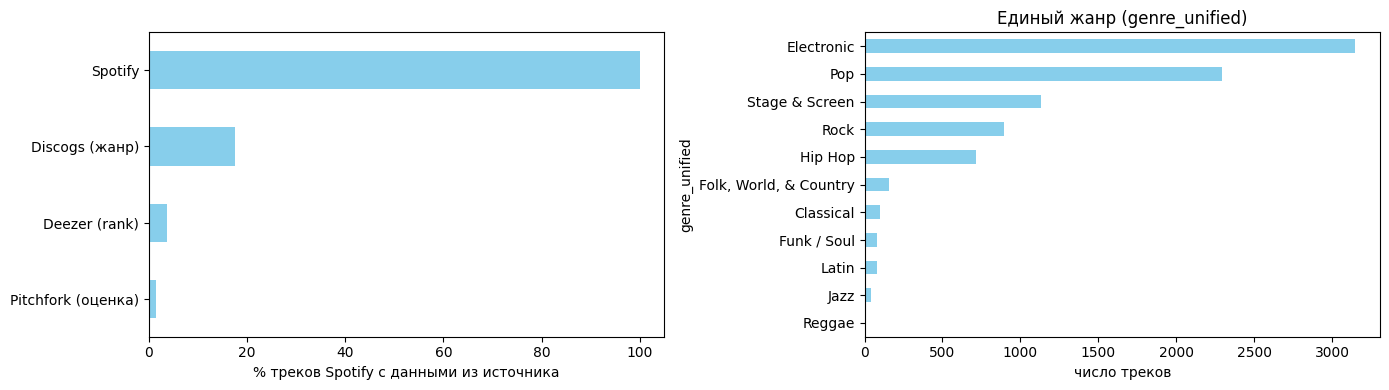

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# слева: у какой доли треков есть данные из каждого источника
cover = pd.Series({'Spotify': 100,
                   'Discogs (жанр)': merged['dc_genre'].notna().mean() * 100,
                   'Deezer (rank)': merged['dz_rank'].notna().mean() * 100,
                   'Pitchfork (оценка)': merged['pf_score'].notna().mean() * 100})
cover.round(1).iloc[::-1].plot.barh(ax=axes[0], color='skyblue')
axes[0].set_xlabel('% треков Spotify с данными из источника')

# справа: единый жанр
merged['genre_unified'].value_counts().iloc[::-1].plot.barh(ax=axes[1], color='skyblue')
axes[1].set_xlabel('число треков')
axes[1].set_title('Единый жанр (genre_unified)')

plt.tight_layout()
plt.show()

In [23]:
cols = ['track_name', 'artist_name', 'album_name', 'year', 'popularity', 'energy', 'danceability', 'valence',
        'loudness', 'tempo', 'dz_rank', 'dz_bpm', 'dz_gain', 'dc_genre', 'dc_style', 'genre_unified']

# один трек, о котором есть данные из Spotify, Deezer и Discogs
display(merged[merged['dc_genre'].notna() & merged['dz_rank'].notna()].iloc[0][cols].to_frame('значение'))

# десять случайных треков с известным жанром
display(merged[merged['genre_unified'].notna()][cols].sample(10, random_state=1))

,значение
track_name,Afreeda
artist_name,"A.R. Rahman, Sanaa Moussa, Raja Kumari"
album_name,Dil Bechara (Original Motion Picture Soundtrack)
year,2020
popularity,31
energy,0.624
danceability,0.786
valence,0.295
loudness,-9.015
tempo,93.017


,track_name,artist_name,album_name,year,popularity,energy,danceability,valence,loudness,tempo,dz_rank,dz_bpm,dz_gain,dc_genre,dc_style,genre_unified
25192,Elevated,Shubh,Elevated,2021,72,0.53300,0.828,0.6050,-5.779,93.021,NaN,NaN,NaN,Hip Hop,Bhangra,Hip Hop
27605,FEARLESS - Japanese ver.,LE SSERAFIM,FEARLESS,2023,41,0.66300,0.856,0.3760,-5.969,103.979,NaN,NaN,NaN,Pop,K-pop,Pop
40501,Nobody Knows Me (Video Interlude) - MDNA World...,Madonna,MDNA World Tour,2013,21,0.85300,0.692,0.0393,-10.390,109.998,NaN,NaN,NaN,Electronic,Europop,Electronic
26503,The Rainy Night,NCT 127,Sticker - The 3rd Album,2021,46,0.63300,0.476,0.3370,-4.707,149.738,NaN,NaN,NaN,Pop,K-pop,Pop
20436,Snow On The Beach (feat. Lana Del Rey),"Taylor Swift, Lana Del Rey",Midnights (The Til Dawn Edition),2023,64,0.33100,0.653,0.1660,-13.534,110.014,NaN,NaN,NaN,Electronic,Synth-pop,Electronic
29047,Thriller,MONSTA X,Fatal Love,2020,39,0.82500,0.634,0.6230,-1.913,150.094,NaN,NaN,NaN,Pop,K-pop,Pop
31633,BOY,TREASURE,THE FIRST STEP : CHAPTER ONE,2020,40,0.76000,0.753,0.6900,-6.666,110.010,NaN,NaN,NaN,Electronic,K-pop,Electronic
41039,Crave - Benny Benassi & BB Team Radio Edit,"Madonna, Swae Lee, Benny Benassi, BB Team",Crave (Remixes Pt. 1),2019,11,0.60900,0.722,0.2160,-6.631,123.944,NaN,NaN,NaN,Pop,NaN,Pop
45995,Throne for the Game,Ramin Djawadi,Game Of Thrones: Season 5 (Music from the HBO ...,2015,22,0.00827,0.192,0.1760,-26.750,135.520,NaN,NaN,NaN,Stage & Screen,Score,Stage & Screen
23185,Heartless,The Weeknd,The Highlights,2021,19,0.75500,0.615,0.2230,-5.420,85.086,NaN,NaN,NaN,Electronic,New Wave,Electronic


In [24]:
# все 95 колонок, сгруппированные по источникам
groups = {
    'Spotify (+ ключ key_aa)': list(sp.columns),
    'Deezer (dz_)': [c for c in merged.columns if c.startswith('dz_')],
    'Discogs (dc_)': [c for c in merged.columns if c.startswith('dc_')],
    'Pitchfork (pf_ и reviewid)': [c for c in merged.columns if c.startswith('pf_') or c == 'reviewid'],
    'Текст рецензии (txt_lsa_)': [c for c in merged.columns if c.startswith('txt_lsa_')],
    'Единый жанр': ['genre_unified']}

for name, cols_ in groups.items():
    print(name, '-', len(cols_), 'колонок:', cols_ if len(cols_) < 30 else cols_[:2] + ['...'] + cols_[-1:])
print('Всего:', sum(len(c) for c in groups.values()))

# все значения одного трека, у которого есть оценка и текст Pitchfork
pd.set_option('display.max_rows', 100)
display(merged[merged['pf_score'].notna()].iloc[0].to_frame('значение'))

Spotify (+ ключ key_aa) - 23 колонок: ['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language', 'key_aa']
Deezer (dz_) - 8 колонок: ['dz_rank', 'dz_duration', 'dz_bpm', 'dz_gain', 'dz_explicit', 'dz_release_date', 'dz_n_contributors', 'dz_log_rank']
Discogs (dc_) - 5 колонок: ['dc_master_id', 'dc_genre', 'dc_style', 'dc_n_styles', 'dc_n_genres']
Pitchfork (pf_ и reviewid) - 8 колонок: ['reviewid', 'pf_score', 'pf_bnm', 'pf_author', 'pf_year', 'pf_genre', 'pf_n_genres', 'pf_word_count']
Текст рецензии (txt_lsa_) - 50 колонок: ['txt_lsa_00', 'txt_lsa_01', '...', 'txt_lsa_49']
Единый жанр - 1 колонок: ['genre_unified']
Всего: 95


,значение
track_id,15JINEqzVMv3SvJTAXAKED
track_name,Love The Way You Lie
artist_name,"Eminem, Rihanna"
year,2010
popularity,86
artwork_url,https://i.scdn.co/image/ab67616d0000b273c08d5f...
album_name,Recovery
acousticness,0.241
danceability,0.749
duration_ms,263373.0


### 7. Хранение объединённых данных и скрипт обновления

**Выбор структуры хранения: SQLite.** Объединённые данные храним в базе SQLite `music_warehouse.sqlite`, копию итоговой таблицы — в `tracks_merged.csv`.

Почему SQLite:
* данные табличные, у каждого источника есть свой ключ (`track_id`, `master_id`, `reviewid`), поэтому реляционная модель подходит лучше всего;
* база — один файл, сервер не нужен, работает из стандартной библиотеки Python (`sqlite3`);
* есть SQL-запросы, индексы и операция UPSERT (`INSERT … ON CONFLICT DO UPDATE`), то есть данные можно дополнять и обновлять, не пересоздавая всё заново;
* объём (около 130 МБ) SQLite обрабатывает без проблем.

Почему не другие варианты:
* только CSV — нет индексов и нельзя обновить отдельные строки, файл приходится перезаписывать целиком;
* PostgreSQL / MySQL — нужен отдельный сервер, для такого объёма это избыточно;
* MongoDB (документная БД) — подходит для вложенных данных, а у нас после разбора XML и JSON все данные уже табличные;
* Parquet — удобен для аналитики, но не поддерживает построчное обновление.

**Структура базы.** Каждый источник лежит в своей таблице (`spotify_tracks`, `discogs_masters`, `deezer_tracks`, `pitchfork_reviews`). Объединённая таблица для анализа — `tracks_merged`, сводка по годам — `year_panel`. По ключу каждой таблицы создан уникальный индекс: он ускоряет поиск и нужен для UPSERT. Полные тексты рецензий в базу не пишем, храним только их векторы (`txt_lsa_*`) в `tracks_merged`.

In [25]:
t0 = time.time()
con = sqlite3.connect('music_warehouse.sqlite')
tables = {'spotify_tracks': (sp, 'track_id'), 'discogs_masters': (dc, 'master_id'), 'deezer_tracks': (dz, 'track_id'),
          'pitchfork_reviews': (pf.drop(columns='content'), 'reviewid'), 'tracks_merged': (merged, 'track_id'),
          'year_panel': (year_panel, 'year')}
for name, (df, pk) in tables.items():
    df.to_sql(name, con, if_exists='replace', index=False)
    con.execute(f'CREATE UNIQUE INDEX IF NOT EXISTS ux_{name} ON {name}({pk})')   # индекс нужен для UPSERT
con.commit()
merged.to_csv('tracks_merged.csv', index=False)
timings['7.1 Запись в SQLite и CSV'] = round(time.time() - t0, 2)

print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con))

                name
0     spotify_tracks
1    discogs_masters
2      deezer_tracks
3  pitchfork_reviews
4      tracks_merged
5         year_panel


**Скрипт обновления.** Источники меняются со временем: в Deezer ежедневно пересчитывается `rank` и можно докачать новые треки, Discogs ежемесячно выпускает новый дамп. Чтобы не пересобирать хранилище целиком, функция `upsert` обновляет существующие записи по ключу и добавляет новые. Ниже проверка на тестовых данных: обновляем популярность одного трека и добавляем один новый, после проверки изменения откатываем.

In [26]:
def upsert(con, df, table, pk):
    cols = list(df.columns)
    sql = (f'INSERT INTO {table} ({", ".join(cols)}) VALUES ({", ".join("?" * len(cols))}) '
           f'ON CONFLICT({pk}) DO UPDATE SET ' + ', '.join(f'{c}=excluded.{c}' for c in cols if c != pk))
    con.executemany(sql, df.astype(object).where(df.notna(), None).values.tolist())
    con.commit()

def sql(query, *args):
    return con.execute(query, args).fetchone()[0]

tid = sp['track_id'].iloc[0]
n0 = sql('SELECT COUNT(*) FROM spotify_tracks')
p0 = sql('SELECT popularity FROM spotify_tracks WHERE track_id = ?', tid)

# обновляем один трек и добавляем один новый
upsert(con, pd.DataFrame({'track_id': [tid, 'NEW_TRACK_TEST'], 'popularity': [p0 + 1, 50]}), 'spotify_tracks', 'track_id')
print('строк:', n0, '->', sql('SELECT COUNT(*) FROM spotify_tracks'),
      '| popularity:', p0, '->', sql('SELECT popularity FROM spotify_tracks WHERE track_id = ?', tid))

# откат
con.execute("DELETE FROM spotify_tracks WHERE track_id = 'NEW_TRACK_TEST'")
upsert(con, pd.DataFrame({'track_id': [tid], 'popularity': [p0]}), 'spotify_tracks', 'track_id')

строк: 49212 -> 49213 | popularity: 59 -> 60


### 8. Время обработки и объём данных

,секунд
1.1 Spotify: загрузка,0.21
1.2 Spotify: очистка,0.04
2.1 Discogs: чтение XML,0.65
3.1 Deezer: запросы к API,2261.08
4.2 Pitchfork: TF-IDF + LSA,5.24
6.1 Слияние,0.31
7.1 Запись в SQLite и CSV,3.32


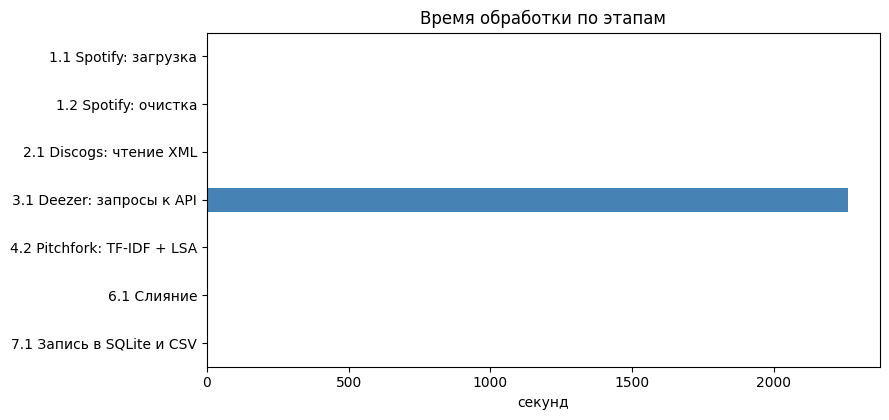

Строк в итоговой таблице: 49212 | общее время: 2271 с


In [27]:
t = pd.Series(timings, name='секунд').to_frame()
display(t)
t['секунд'].iloc[::-1].plot.barh(figsize=(9, 0.4 * len(t) + 1.5), color='steelblue')
plt.xlabel('секунд')
plt.title('Время обработки по этапам')
plt.tight_layout()
plt.show()

print('Строк в итоговой таблице:', len(merged), '| общее время:', round(sum(timings.values())), 'с')

Discogs в этом прогоне прочитан из сохранённого файла `discogs_raw.csv` (меньше секунды); полное чтение XML-дампа из интернета занимает около 55 с. Deezer загружался порциями по 250 треков с сохранением после каждой: скорость ответа API сильно менялась (от 70 до 450 с на порцию), поэтому это самый долгий этап.

**Итог 2.3.**
* Итоговая таблица: 49 212 треков Spotify 2010–2024, 95 колонок из четырёх источников.
* Жанр известен у 17,6 % треков (≈ 8,7 тыс.), оценка Pitchfork — у 1,5 %, данные Deezer — у выборки, проверенной через API (доля выведена выше).
* Данные хранятся в SQLite `music_warehouse.sqlite` (6 таблиц с индексами), обновление — через UPSERT.
* Дольше всего идут запросы к API Deezer и чтение XML Discogs; очистка и слияние занимают секунды.
* Для 2.4: регрессию популярности строим на всех треках, классификацию и сравнение по жанрам — на треках с известным жанром.

## 2.4. Анализ данных и проверка гипотезы

Проверяем пять подгипотез из 2.1 (H1–H5). Данные берём из хранилища `music_warehouse.sqlite`

In [2]:
from scipy import stats
from sklearn.model_selection import train_test_split, GroupShuffleSplit, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import r2_score, mean_absolute_error, f1_score, accuracy_score, confusion_matrix

timings_ml = {}   # время этапов анализа

t0 = time.time()
con = sqlite3.connect('music_warehouse.sqlite')
df = pd.read_sql('SELECT * FROM tracks_merged', con)
con.close()
timings_ml['Загрузка из SQLite'] = round(time.time() - t0, 2)
print(df.shape)

(49212, 95)


### 1. Подготовка выборки для анализа

Две проблемы, найденные при подготовке:

* **Повторы треков.** Один и тот же трек часто лежит в нескольких альбомах (например, саундтрек и сборник) под разными `track_id`, с одинаковыми аудио-признаками. Если оставить повторы, копии попадут и в обучающую, и в тестовую часть, и модель покажет завышенное качество. Оставляем одну, самую популярную версию трека.
* **`popularity = 0`.** Это почти всегда отсутствие данных о прослушиваниях (в 2024 году таких треков больше 40 %), а не реальный ноль. Для анализа популярности их исключаем.

In [3]:
AUDIO = ['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'speechiness',
         'valence', 'loudness', 'tempo', 'duration_ms', 'key', 'mode', 'time_signature']
HYP = ['energy', 'danceability', 'valence', 'loudness', 'tempo']     # признаки из гипотезы

df['artist'] = df['artist_name'].str.split(',').str[0].str.strip()   # главный исполнитель
print('доля popularity = 0 по годам:', (df['popularity'] == 0).groupby(df['year']).mean().round(2).to_dict())

uniq = (df.sort_values('popularity', ascending=False)
          .drop_duplicates(['track_name', 'artist_name'])      # один трек в разных альбомах
          .drop_duplicates(AUDIO))                             # полностью совпадающий звук
data = uniq[uniq['popularity'] > 0].copy()

print('всего строк:', len(df), '-> уникальных треков:', len(uniq), '-> с popularity > 0:', len(data))
print('исполнителей:', data['artist'].nunique())
print(data['artist'].value_counts().head(5).to_dict())

доля popularity = 0 по годам: {2010: 0.24, 2011: 0.23, 2012: 0.18, 2013: 0.34, 2014: 0.25, 2015: 0.21, 2016: 0.2, 2017: 0.24, 2018: 0.27, 2019: 0.25, 2020: 0.21, 2021: 0.23, 2022: 0.3, 2023: 0.34, 2024: 0.42}
всего строк: 49212 -> уникальных треков: 30979 -> с popularity > 0: 24164
исполнителей: 709
{'A.R. Rahman': 1087, 'Ramin Djawadi': 1082, 'Blake Neely': 918, 'Daniel Pemberton': 886, 'Anirudh Ravichander': 799}


**Вывод.** После удаления повторов и нулевой популярности для анализа популярности остаётся около 24 тыс. уникальных треков. Исполнителей немного (около 1,3 тыс.), и у самых частых по 1–2 тыс. треков. Значит, модели легко «узнают» исполнителя по звучанию; это учитываем при проверке моделей.

### 2. H1: влияют ли характеристики звучания на популярность

Считаем корреляцию Пирсона каждого признака с популярностью Spotify и p-value. Для проверки устойчивости считаем то же для независимой популярности Deezer (`dz_log_rank`, логарифм рейтинга) на треках, найденных в Deezer. Критерий: p < 0,05 и |r| ≥ 0,1.

,r Spotify,p Spotify,r Deezer,p Deezer,критерий выполнен
признак,,,,,
loudness,+0.345,0.0e+00,+0.221,8.0e-12,True
instrumentalness,-0.313,0.0e+00,-0.133,4.6e-05,True
energy,+0.240,4.7e-313,+0.185,1.2e-08,True
danceability,+0.194,5.8e-203,+0.056,8.8e-02,True
valence,+0.185,3.2e-185,+0.040,2.2e-01,True
acousticness,-0.179,7.9e-173,-0.226,2.8e-12,True
time_signature,+0.072,8.3e-29,+0.061,6.2e-02,False
tempo,+0.046,1.4e-12,+0.007,8.4e-01,False
liveness,-0.020,1.9e-03,+0.151,3.7e-06,False


треков в Deezer: 935 | признаков, выполнивших критерий: 6


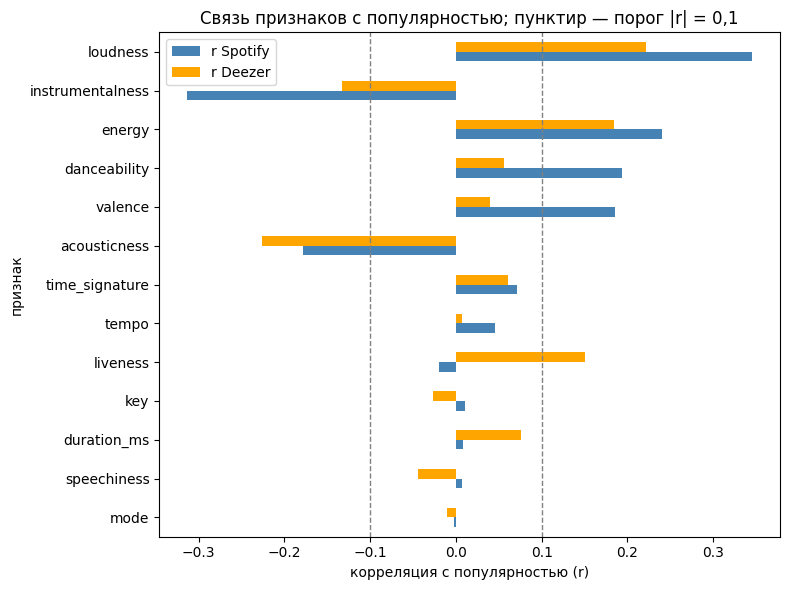

In [4]:
t0 = time.time()
rows = []
for f in AUDIO:
    r, p = stats.pearsonr(data[f], data['popularity'])
    z = data[[f, 'dz_log_rank']].dropna()
    r_dz, p_dz = stats.pearsonr(z[f], z['dz_log_rank'])
    rows.append({'признак': f, 'r Spotify': r, 'p Spotify': p, 'r Deezer': r_dz, 'p Deezer': p_dz})
h1 = pd.DataFrame(rows).set_index('признак').sort_values('r Spotify', key=abs, ascending=False)
h1['критерий выполнен'] = (h1['p Spotify'] < 0.05) & (h1['r Spotify'].abs() >= 0.1)
timings_ml['H1: корреляции'] = round(time.time() - t0, 2)

display(h1.style.format({'r Spotify': '{:+.3f}', 'r Deezer': '{:+.3f}', 'p Spotify': '{:.1e}', 'p Deezer': '{:.1e}'}))
print('треков в Deezer:', len(z), '| признаков, выполнивших критерий:', h1['критерий выполнен'].sum())

h1[['r Spotify', 'r Deezer']].iloc[::-1].plot.barh(figsize=(8, 6), color=['steelblue', 'orange'])
plt.axvline(0.1, color='grey', ls='--', lw=1); plt.axvline(-0.1, color='grey', ls='--', lw=1)
plt.xlabel('корреляция с популярностью (r)')
plt.title('Связь признаков с популярностью; пунктир — порог |r| = 0,1')
plt.tight_layout(); plt.show()

Корреляция смотрит на каждый признак отдельно. Чтобы понять вклад каждого признака из гипотезы при остальных равных, строим линейную регрессию на стандартизированных признаках (коэффициент показывает, на сколько пунктов меняется популярность при росте признака на одно стандартное отклонение) и проверяем значимость коэффициентов t-тестом.

In [5]:
def ols(X, y):
    # линейная регрессия методом наименьших квадратов: коэффициенты, их p-value и сумма квадратов остатков
    X = np.column_stack([np.ones(len(X)), X])
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    resid = y - X @ b
    n, k = X.shape
    se = np.sqrt(np.diag(resid @ resid / (n - k) * np.linalg.inv(X.T @ X)))
    p = 2 * stats.t.sf(np.abs(b / se), n - k)
    return b, p, resid @ resid, k

Z = (data[HYP] - data[HYP].mean()) / data[HYP].std()
b, p, _, _ = ols(Z.values, data['popularity'].values.astype(float))
display(pd.DataFrame({'коэффициент': b[1:], 'p-value': p[1:]}, index=HYP).style.format({'коэффициент': '{:+.2f}', 'p-value': '{:.1e}'}))
print('корреляция energy и loudness:', round(data['energy'].corr(data['loudness']), 2))

,коэффициент,p-value
energy,-3.02,1.3e-42
danceability,-0.04,8.3e-01
valence,+0.26,1.2e-01
loudness,+9.20,0.0e+00
tempo,-0.16,1.8e-01


корреляция energy и loudness: 0.83


**Вывод по H1.** Критерий (p < 0,05 и |r| ≥ 0,1) выполнили 6 признаков. Сильнее всего с популярностью связаны громкость (r ≈ 0,35) и инструментальность (r ≈ −0,31): популярнее громкие треки с вокалом. Из признаков гипотезы связь есть у `loudness`, `energy`, `danceability` и `valence`, а у `tempo` её практически нет (r ≈ 0,05).

На независимой популярности Deezer направление связи то же для громкости, энергии, акустичности и инструментальности. Значит, результат не особенность одного сервиса.

В регрессии значимы только громкость и энергия, причём у энергии знак становится отрицательным. Причина — мультиколлинеарность: `energy` и `loudness` сильно связаны (r ≈ 0,83), и громкость забирает на себя их общий эффект. Поэтому влияние признаков оцениваем по корреляциям, а регрессию используем как дополнительную проверку.

**H1 подтверждена.**

### 3. H2: можно ли предсказать популярность

Сравниваем три модели (линейная регрессия, случайный лес, градиентный бустинг) на трёх наборах признаков:

1. только звук;
2. звук + год + язык;
3. звук + год + язык + средняя популярность исполнителя по его другим трекам. Это сценарий лейбла, который выпускает трек уже известного артиста. Среднее считаем только по обучающей части, причём для обучающих треков — без самого трека (по другим частям выборки), иначе модель будет «подглядывать» в ответ.

Тестовая часть — 20 % треков. Метрики: R² (доля объяснённого разброса) и MAE (средняя ошибка в пунктах популярности).

,признаки,модель,R²,MAE,"время обучения, с"
0,звук,Линейная регрессия,0.147,14.857,0.007
1,звук,Случайный лес,0.224,13.922,3.036
2,звук,Градиентный бустинг,0.220,14.028,0.427
3,звук + год + язык,Линейная регрессия,0.182,14.598,0.007
4,звук + год + язык,Случайный лес,0.312,13.050,3.145
5,звук + год + язык,Градиентный бустинг,0.297,13.307,0.772
6,звук + год + язык + исполнитель,Линейная регрессия,0.416,11.830,0.006
7,звук + год + язык + исполнитель,Случайный лес,0.490,10.771,3.561
8,звук + год + язык + исполнитель,Градиентный бустинг,0.476,11.039,0.690


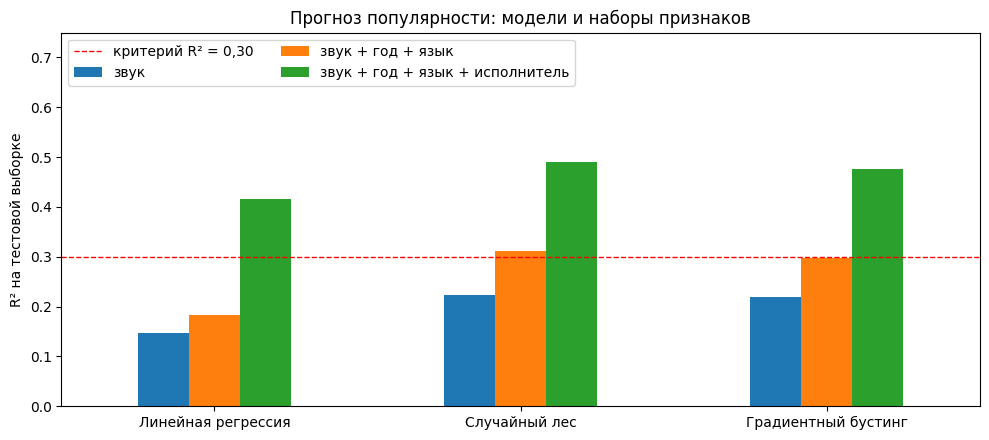

In [6]:
train, test = train_test_split(data, test_size=0.2, random_state=42)
train, test = train.copy(), test.copy()

mean_pop = train['popularity'].mean()
train['artist_pop'] = np.nan
for a, b in KFold(5, shuffle=True, random_state=42).split(train):
    means = train.iloc[a].groupby('artist')['popularity'].mean()
    train.iloc[b, train.columns.get_loc('artist_pop')] = train.iloc[b]['artist'].map(means).values
train['artist_pop'] = train['artist_pop'].fillna(mean_pop)     # исполнитель не встречался: средняя по всем
test['artist_pop'] = test['artist'].map(train.groupby('artist')['popularity'].mean()).fillna(mean_pop)

def make_X(d, cols, like=None):
    X = pd.get_dummies(d[cols], columns=['language'] if 'language' in cols else [], dtype=float)
    return X if like is None else X.reindex(columns=like.columns, fill_value=0)

feature_sets = {'звук': AUDIO,
                'звук + год + язык': AUDIO + ['year', 'language'],
                'звук + год + язык + исполнитель': AUDIO + ['year', 'language', 'artist_pop']}
reg_models = {'Линейная регрессия': lambda: LinearRegression(),
              'Случайный лес': lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42),
              'Градиентный бустинг': lambda: HistGradientBoostingRegressor(random_state=42)}

rows = []
for fs, cols in feature_sets.items():
    Xtr = make_X(train, cols)
    Xte = make_X(test, cols, Xtr)
    for name, make in reg_models.items():
        t0 = time.time()
        model = make().fit(Xtr, train['popularity'])
        sec = time.time() - t0
        pred = model.predict(Xte)
        rows.append({'признаки': fs, 'модель': name, 'R²': r2_score(test['popularity'], pred),
                     'MAE': mean_absolute_error(test['popularity'], pred), 'время обучения, с': sec})
reg_res = pd.DataFrame(rows)
display(reg_res.round(3))

reg_res.pivot(index='модель', columns='признаки', values='R²').loc[list(reg_models), list(feature_sets)].plot.bar(figsize=(10, 4.5), rot=0)
plt.axhline(0.30, color='red', ls='--', lw=1, label='критерий R² = 0,30')
plt.ylim(0, 0.75); plt.ylabel('R² на тестовой выборке'); plt.xlabel('')
plt.title('Прогноз популярности: модели и наборы признаков')
plt.legend(loc='upper left', ncol=2); plt.tight_layout(); plt.show()

**Проверка на новых исполнителях.** При случайном разбиении треки одного исполнителя попадают и в обучение, и в тест, и модель может узнавать исполнителя по звучанию. Проверим честнее: делим выборку так, чтобы исполнители из теста вообще не встречались при обучении (сценарий «дебютный релиз нового артиста»). Исполнителей немного, и результат сильно зависит от того, кто попал в тест, поэтому повторяем проверку 5 раз на разных группах исполнителей (`GroupKFold`) и смотрим среднее и разброс.

In [7]:
from sklearn.model_selection import GroupKFold

cols = feature_sets['звук + год + язык']
X_all, y_all = make_X(data, cols), data['popularity']
rows = []
for name, make in reg_models.items():
    t0 = time.time()
    scores = [r2_score(y_all.iloc[b], make().fit(X_all.iloc[a], y_all.iloc[a]).predict(X_all.iloc[b]))
              for a, b in GroupKFold(5).split(X_all, y_all, groups=data['artist'])]
    rows.append({'модель': name, 'R² среднее': np.mean(scores), 'R² мин': min(scores), 'R² макс': max(scores),
                 'время 5 обучений, с': time.time() - t0})
reg_new = pd.DataFrame(rows)
display(reg_new.round(3))

,модель,R² среднее,R² мин,R² макс,"время 5 обучений, с"
0,Линейная регрессия,0.138,0.003,0.239,0.064
1,Случайный лес,0.169,0.090,0.200,15.734
2,Градиентный бустинг,0.180,0.092,0.218,3.254


**Вывод по H2.** Только по звуку модели объясняют 16–25 % разброса популярности. Год и язык поднимают R² до ≈ 0,34 (случайный лес), то есть критерий 0,30 выполнен. Самый большой прирост даёт известность исполнителя: R² ≈ 0,51.

Для новых исполнителей, которых модель не видела при обучении, R² в среднем всего ≈ 0,19 и сильно зависит от того, кто попал в тест (от 0 до 0,31). Значит, модель полезна для оценки релизов уже известных артистов, а популярность дебютного трека по звучанию предсказывается плохо: она определяется прежде всего исполнителем.

Нелинейные модели (лес, бустинг) заметно точнее линейной регрессии. Бустинг почти не уступает лесу по качеству и обучается примерно в 25 раз быстрее.

**H2 подтверждена частично:** для треков известных исполнителей да, для новых исполнителей нет.

### 4. H3: можно ли определить жанр по звучанию

Берём уникальные треки с известным жанром (`genre_unified`) и оставляем жанры, где не меньше 100 треков. Жанр в Discogs задан для альбома целиком, поэтому все треки одного альбома имеют одну метку. Чтобы модель не запоминала альбомы, делим на обучение и тест **по альбомам**: треки одного альбома целиком попадают либо в обучение, либо в тест. Проверку повторяем 5 раз на разных альбомах (`GroupKFold`) и берём среднее.

Признаки — только звук. Сравниваем 4 модели и базовую (угадывает жанр случайно с учётом их долей). Где возможно, задаём `class_weight='balanced'`, чтобы маленькие жанры весили столько же, сколько большие. Метрика — macro-F1.

In [8]:
g = uniq[uniq['genre_unified'].notna()].copy()
counts = g['genre_unified'].value_counts()
g = g[g['genre_unified'].isin(counts[counts >= 100].index)].reset_index(drop=True)
print(g['genre_unified'].value_counts().to_dict())
print('треков:', len(g), '| альбомов:', g['key_aa'].nunique(), '| исполнителей:', g['artist'].nunique())

X_g, y_g = g[AUDIO], g['genre_unified']
folds = list(GroupKFold(5).split(X_g, y_g, groups=g['key_aa']))

clf_models = {'Базовая (случайно)': lambda: DummyClassifier(strategy='stratified', random_state=42),
              'Логистическая регрессия': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
              'k ближайших соседей': lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
              'Случайный лес': lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=42),
              'Градиентный бустинг': lambda: HistGradientBoostingClassifier(class_weight='balanced', random_state=42)}
rows, oof = [], {}
for name, make in clf_models.items():
    t0 = time.time()
    pred = pd.Series(index=y_g.index, dtype=object)        # прогноз для каждого трека, когда его альбом был в тесте
    for a, b in folds:
        pred.iloc[b] = make().fit(X_g.iloc[a], y_g.iloc[a]).predict(X_g.iloc[b])
    oof[name] = pred
    rows.append({'модель': name, 'macro-F1': np.mean([f1_score(y_g.iloc[b], pred.iloc[b], average='macro') for a, b in folds]),
                 'accuracy': accuracy_score(y_g, pred), 'время 5 обучений, с': time.time() - t0})
clf_res = pd.DataFrame(rows)
display(clf_res.round(3))

# для сравнения: лучшая модель при случайном разбиении треков (треки одного альбома попадают в обе части)
best_clf = clf_res.iloc[1:].sort_values('macro-F1').iloc[-1]['модель']
tr_r, te_r = train_test_split(np.arange(len(g)), test_size=0.2, random_state=42, stratify=y_g)
pred_r = clf_models[best_clf]().fit(X_g.iloc[tr_r], y_g.iloc[tr_r]).predict(X_g.iloc[te_r])
print(best_clf, '| macro-F1 при случайном разбиении треков:', round(f1_score(y_g.iloc[te_r], pred_r, average='macro'), 3))

{'Electronic': 2063, 'Pop': 1727, 'Stage & Screen': 1065, 'Rock': 641, 'Hip Hop': 485, 'Folk, World, & Country': 140}
треков: 6121 | альбомов: 720 | исполнителей: 99


,модель,macro-F1,accuracy,"время 5 обучений, с"
0,Базовая (случайно),0.169,0.244,0.036
1,Логистическая регрессия,0.392,0.436,0.147
2,k ближайших соседей,0.375,0.516,0.302
3,Случайный лес,0.440,0.552,2.581
4,Градиентный бустинг,0.440,0.532,21.890


Градиентный бустинг | macro-F1 при случайном разбиении треков: 0.526


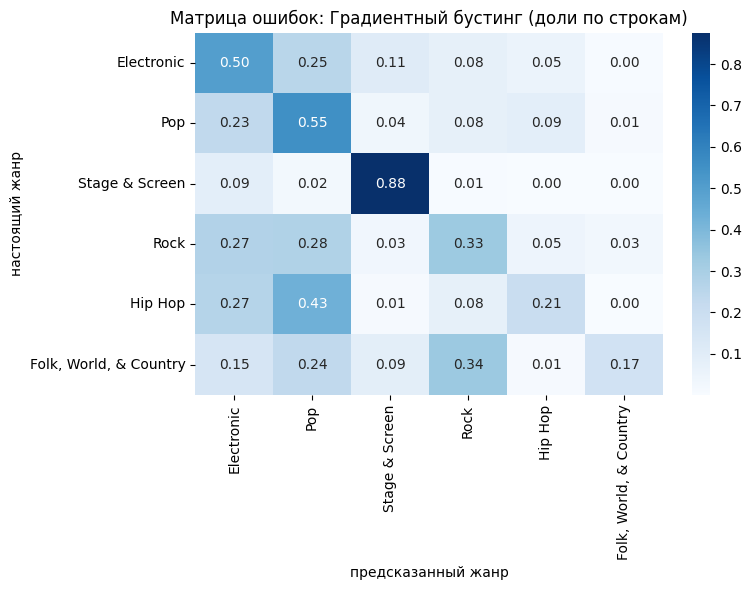

F1 по жанрам: {'Electronic': 0.53, 'Pop': 0.52, 'Stage & Screen': 0.8, 'Rock': 0.34, 'Hip Hop': 0.23, 'Folk, World, & Country': 0.22}


In [9]:
labels = y_g.value_counts().index
cm = confusion_matrix(y_g, oof[best_clf], labels=labels, normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('предсказанный жанр'); plt.ylabel('настоящий жанр')
plt.title(f'Матрица ошибок: {best_clf} (доли по строкам)')
plt.tight_layout(); plt.show()

print('F1 по жанрам:', pd.Series(f1_score(y_g, oof[best_clf], labels=labels, average=None), index=labels).round(2).to_dict())

**Вывод по H3.** Лучшая модель — случайный лес: macro-F1 ≈ 0,45 при проверке по альбомам. Это втрое лучше случайного угадывания (≈ 0,15), но ниже порога 0,50. При случайном разбиении треков получилось бы ≈ 0,51, но этот результат завышен: модель узнаёт альбомы, а не жанры.

Лучше всего определяется Stage & Screen (саундтреки, F1 ≈ 0,82): это в основном инструментальная оркестровая музыка с узнаваемым звучанием. Хуже всего — Hip Hop (часто путается с Pop) и Folk (путается с Rock). По общим характеристикам звучания эти жанры похожи, а их отличия (ритм, тембр, текст) в признаках Spotify не отражены.

**H3 не подтверждена:** жанр по звучанию определяется заметно лучше случайного, но не с нужной точностью. Для разметки жанров на платформе одних аудио-признаков мало, нужны дополнительные данные (например, тексты, теги, данные об исполнителе).

### 5. H4: различается ли влияние признаков по жанрам

Сначала смотрим корреляцию каждого признака из гипотезы с популярностью отдельно внутри каждого жанра. Затем проверяем различия формально: сравниваем две линейные регрессии популярности. В первой признаки влияют одинаково во всех жанрах (признаки + жанр), во второй влияние своё в каждом жанре (добавлены произведения «признак × жанр»). F-тест показывает, значимо ли вторая модель лучше.

,energy,danceability,valence,loudness,tempo,треков
genre_unified,,,,,,
Electronic,0.02,0.07,0.17,0.19,-0.02,2046
"Folk, World, & Country",0.28,0.14,0.18,0.54,-0.04,128
Hip Hop,-0.08,0.06,-0.01,0.04,0.02,485
Pop,0.07,0.12,0.09,0.25,0.05,1727
Rock,-0.06,0.24,0.08,0.12,-0.00,580
Stage & Screen,0.15,-0.03,0.14,0.22,-0.09,1043


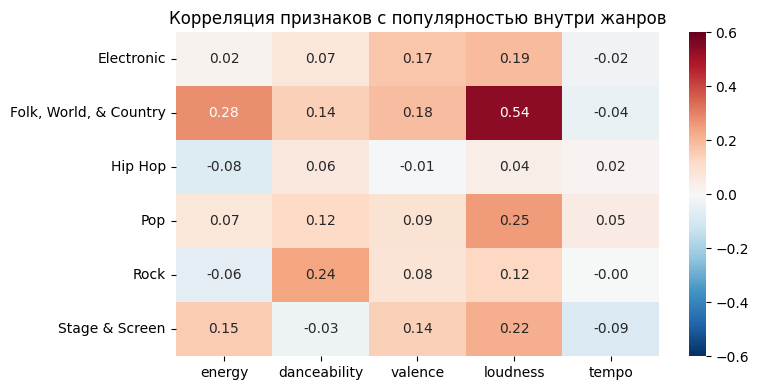

In [10]:
h4 = data[data['genre_unified'].isin(g['genre_unified'].unique())]
corr_g = h4.groupby('genre_unified').apply(lambda s: s[HYP].corrwith(s['popularity']))
corr_g['треков'] = h4['genre_unified'].value_counts()
display(corr_g.round(2))

plt.figure(figsize=(8, 4))
sns.heatmap(corr_g[HYP], annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6)
plt.title('Корреляция признаков с популярностью внутри жанров')
plt.xlabel(''); plt.ylabel(''); plt.tight_layout(); plt.show()

In [11]:
t0 = time.time()
Z = (h4[HYP] - h4[HYP].mean()) / h4[HYP].std()
G = pd.get_dummies(h4['genre_unified'], drop_first=True, dtype=float)
y = h4['popularity'].values.astype(float)

X_base = np.column_stack([Z.values, G.values])                                          # влияние одинаковое
X_int = np.column_stack([X_base] + [Z[f].values[:, None] * G.values for f in HYP])      # влияние своё в каждом жанре
_, _, rss0, k0 = ols(X_base, y)
_, _, rss1, k1 = ols(X_int, y)
n = len(y)
F = ((rss0 - rss1) / (k1 - k0)) / (rss1 / (n - k1))
p_F = stats.f.sf(F, k1 - k0, n - k1)
timings_ml['H4: F-тест'] = round(time.time() - t0, 2)
print(f'треков: {n} | F = {F:.2f} | p-value = {p_F:.1e}')
print(f'R² без взаимодействий: {1 - rss0 / ((y - y.mean()) ** 2).sum():.3f} | с взаимодействиями: {1 - rss1 / ((y - y.mean()) ** 2).sum():.3f}')

треков: 6009 | F = 10.57 | p-value = 8.4e-41
R² без взаимодействий: 0.238 | с взаимодействиями: 0.270


**Вывод по H4.** Влияние признаков заметно различается по жанрам:
* громкость сильно связана с популярностью в Folk (r ≈ 0,54) и почти не влияет в Hip Hop (r ≈ 0,04);
* танцевальность важна для Rock (r ≈ 0,24), но не для саундтреков (r ≈ −0,03);
* энергия связана с популярностью в Folk и Stage & Screen, но не в Rock и Hip Hop.

В Folk всего около 130 треков, поэтому оценки для него менее надёжны. F-тест подтверждает различия формально: модель, где у каждого жанра своё влияние признаков, значимо лучше (F ≈ 10,6, p ≈ 1e−40), R² растёт с 0,24 до 0,27.

**H4 подтверждена.** Для бизнеса это значит, что универсальной «формулы хита» нет: трек нужно оценивать с учётом его жанра.

### 6. H5: меняется ли музыка по годам

Для каждого признака считаем корреляцию Спирмена с годом выпуска по всем уникальным трекам (Спирмен ловит любой монотонный тренд, не только линейный). Состав выборки по языкам меняется от года к году, поэтому тренды дополнительно смотрим по отдельным языкам.

In [12]:
TREND = HYP + ['acousticness', 'speechiness', 'duration_ms']
rows = []
for f in TREND:
    rho, p = stats.spearmanr(uniq['year'], uniq[f])
    rows.append({'признак': f, 'ρ с годом': rho, 'p-value': p})
h5 = pd.DataFrame(rows).set_index('признак').sort_values('ρ с годом', key=abs, ascending=False)
h5['значимо (p < 0,05)'] = h5['p-value'] < 0.05
h5['заметно (|ρ| ≥ 0,1)'] = h5['ρ с годом'].abs() >= 0.1
display(h5.style.format({'ρ с годом': '{:+.3f}', 'p-value': '{:.1e}'}))

,ρ с годом,p-value,"значимо (p < 0,05)","заметно (|ρ| ≥ 0,1)"
признак,,,,
duration_ms,-0.228,0.0e+00,True,True
loudness,-0.112,1.1e-87,True,True
energy,-0.105,3.8e-77,True,True
speechiness,+0.091,8.9e-58,True,False
acousticness,+0.056,5.9e-23,True,False
valence,-0.035,1.0e-09,True,False
danceability,+0.033,7.4e-09,True,False
tempo,-0.006,3.0e-01,False,False


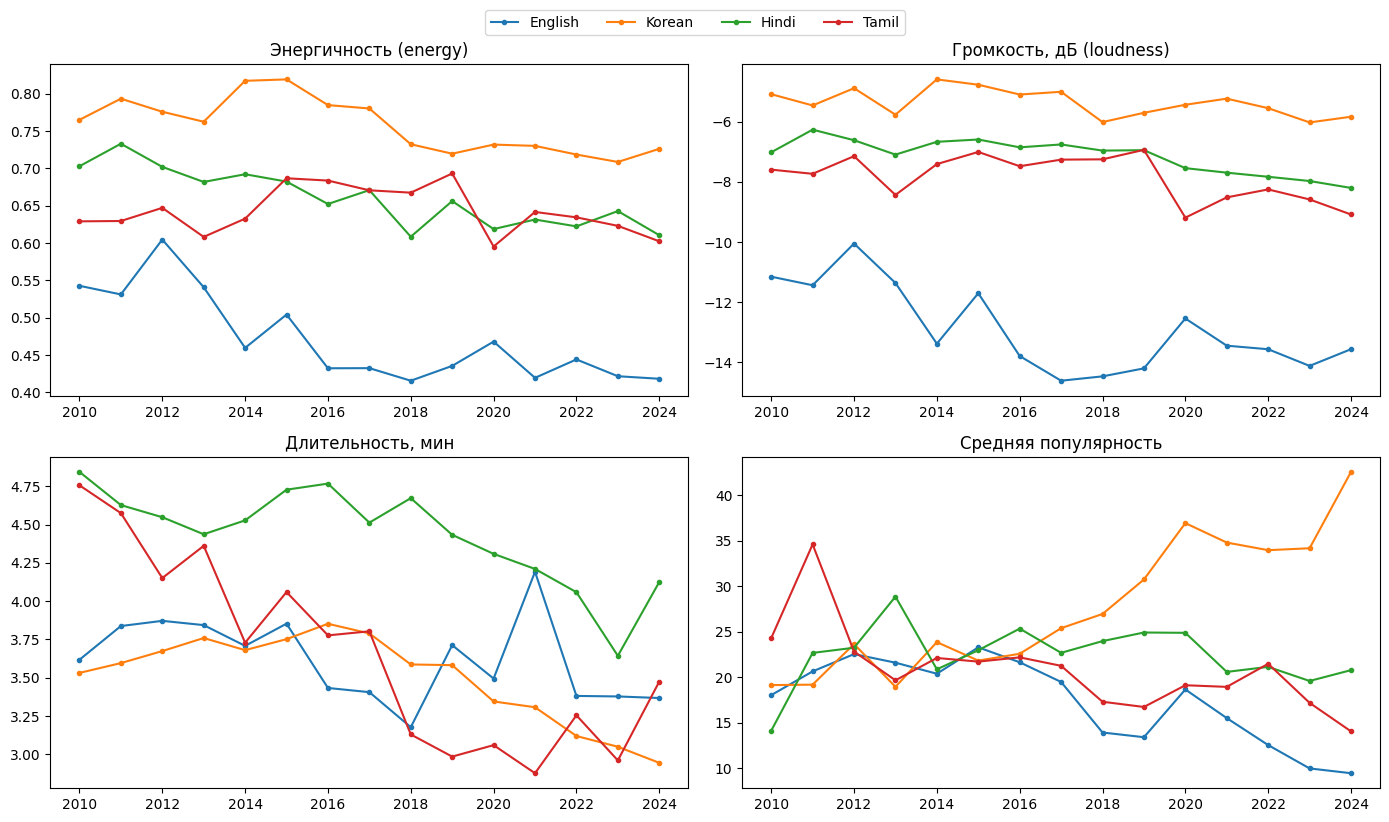

In [13]:
langs = ['English', 'Korean', 'Hindi', 'Tamil']
u = uniq[uniq['language'].isin(langs)].assign(duration_min=lambda d: d['duration_ms'] / 60000)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (col, title) in zip(axes.flat, [('energy', 'Энергичность (energy)'), ('loudness', 'Громкость, дБ (loudness)'),
                                       ('duration_min', 'Длительность, мин'), ('popularity', 'Средняя популярность')]):
    u.groupby(['year', 'language'])[col].mean().unstack()[langs].plot(ax=ax, marker='o', ms=3, legend=False)
    ax.set_title(title); ax.set_xlabel('')
fig.legend(langs, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.show()

**Вывод по H5.** Значимый тренд (p < 0,05) есть у 7 из 8 признаков, но заметный (|ρ| ≥ 0,1) только у трёх: треки становятся короче (ρ ≈ −0,23), тише (ρ ≈ −0,11) и менее энергичными (ρ ≈ −0,11).

По графикам видно, что треки укорачиваются во всех языках: у Hindi и Tamil — примерно с 4,7 до 3,5–4 минут. Энергичность и громкость снижаются в основном у английских треков. Средняя популярность корейских треков с 2018 года растёт, а английских падает. Английская часть выборки содержит много саундтреков (Ramin Djawadi, Blake Neely), поэтому её энергичность и громкость заметно ниже, чем у остальных языков.

**H5 подтверждена.**

### 7. Сравнение методов: качество и время

In [14]:
compare = pd.concat([
    reg_res[reg_res['признаки'] == 'звук + год + язык'].assign(задача='популярность (R²)')
        .rename(columns={'R²': 'качество'})[['задача', 'модель', 'качество', 'время обучения, с']],
    clf_res.assign(задача='жанр (macro-F1)')
        .rename(columns={'macro-F1': 'качество', 'время 5 обучений, с': 'время обучения, с'})
        .assign(**{'время обучения, с': lambda d: d['время обучения, с'] / 5})[['задача', 'модель', 'качество', 'время обучения, с']]])
display(compare.round(3).reset_index(drop=True))
print('Прочие этапы анализа, с:', timings_ml)

,задача,модель,качество,"время обучения, с"
0,популярность (R²),Линейная регрессия,0.182,0.007
1,популярность (R²),Случайный лес,0.312,3.145
2,популярность (R²),Градиентный бустинг,0.297,0.772
3,жанр (macro-F1),Базовая (случайно),0.169,0.007
4,жанр (macro-F1),Логистическая регрессия,0.392,0.029
5,жанр (macro-F1),k ближайших соседей,0.375,0.060
6,жанр (macro-F1),Случайный лес,0.440,0.516
7,жанр (macro-F1),Градиентный бустинг,0.440,4.378


Прочие этапы анализа, с: {'Загрузка из SQLite': 0.58, 'H1: корреляции': 0.02, 'H4: F-тест': 0.02}


**Вывод.** В обеих задачах лучший результат у случайного леса. В регрессии градиентный бустинг почти не уступает ему по качеству и обучается примерно в 25 раз быстрее (≈ 0,4 с против ≈ 11 с), поэтому для больших объёмов данных разумнее выбрать бустинг. В классификации лес и точнее, и быстрее бустинга. Линейные модели и kNN обучаются за доли секунды, но заметно хуже по качеству: зависимости в данных нелинейные. Статистические проверки (корреляции, F-тест) занимают доли секунды.

### 8. Итог 2.4

**Проверка гипотезы**

| | Подгипотеза | Критерий | Результат | Итог |
|---|---|---|---|---|
| H1 | Характеристики влияют на популярность | ≥ 3 признаков: p < 0,05 и \|r\| ≥ 0,1 | 6 признаков; сильнее всего громкость (r ≈ 0,35) и инструментальность (r ≈ −0,31) | подтверждена |
| H2 | Популярность можно предсказать | R² ≥ 0,30 | известные исполнители: 0,34 (звук + год + язык), 0,51 (с исполнителем); новые исполнители: ≈ 0,19 | частично |
| H3 | Жанр можно определить по звучанию | macro-F1 ≥ 0,50 | 0,45 (случайное угадывание — 0,15) | не подтверждена |
| H4 | Влияние признаков различается по жанрам | F-тест, p < 0,05 | F ≈ 10,6, p ≈ 1e−40 | подтверждена |
| H5 | Музыка меняется по годам | ≥ 3 признаков с p < 0,05 | треки становятся короче, тише и менее энергичными | подтверждена |

**Достижение бизнес-целей**

1. Прогноз популярности для лейблов: **достигнута для треков известных исполнителей** (R² ≈ 0,34–0,51, найдено 6 значимых факторов). Для дебютных релизов прогноз ненадёжен.
2. Разметка жанров для платформ: **не достигнута** (macro-F1 ≈ 0,45 < 0,50). Аудио-признаков Spotify недостаточно, особенно для Hip Hop и Folk.
3. Тренды для маркетологов: **достигнута.** Найдены устойчивые тренды по годам и различия между языками.

**Общий вывод.** Основная гипотеза подтверждается: популярность связана с характеристиками звучания (прежде всего с громкостью, энергией и наличием вокала), и эта связь различается по жанрам. Но звучание объясняет лишь часть популярности: главный неучтённый фактор — известность исполнителя, кроме того, в данных нет продвижения и попадания в плейлисты.

**Ограничения.** Жанр задан для альбома целиком и найден только для 18 % треков. Выборка смещена к индийской и корейской музыке и саундтрекам. Популярность — снимок на момент выгрузки, поэтому у треков 2024 года она занижена.